# **Assignment 1: Implementation of Two Libraries - Tensorflow and Keras - 1. Dataset split 2. Training 3. Evaluation**

In [1]:
# 1. Importing Libraries
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

In [2]:
# 2. Get data and split into train and test datasets
(X_train, y_train), (X_test, y_test) = tf.keras.datasets.fashion_mnist.load_data()

print("Training Images Shape :", X_train.shape)
print("Training Labels Shape :", y_train.shape)

print("Testing Images Shape :", X_test.shape)
print("Testing Labels Shape :", y_test.shape)


29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training Images Shape : (60000, 28, 28)
Training Labels Shape : (60000,)
Testing Images Shape : (10000, 28, 28)
Testing Labels Shape : (10000,)


In [3]:
# 3. Scale down values of pixels from 0-255 to 0-1
print("Pixel Value Range :", X_train.min(), "to", X_train.max())
X_train = X_train / 255.0
X_test = X_test / 255.0
print("New Pixel Value Range:")
print("Minimum:", X_train.min())
print("Maximum:", X_train.max())

Pixel Value Range : 0 to 255
New Pixel Value Range:
Minimum: 0.0
Maximum: 1.0


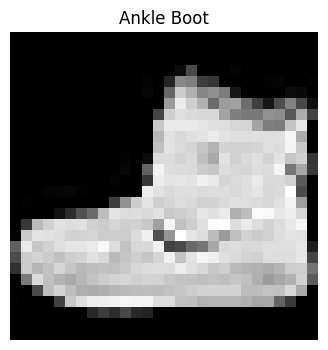

In [4]:
# 4. Visualizing data
class_names = [
    "T-shirt/Top",
    "Trouser",
    "Pullover",
    "Dress",
    "Coat",
    "Sandal",
    "Shirt",
    "Sneaker",
    "Bag",
    "Ankle Boot"
]

# Display first image
plt.figure(figsize=(4,4))
plt.imshow(X_train[0], cmap="gray")
plt.title(class_names[y_train[0]])
plt.axis("off")
plt.show()

In [5]:
# Defining neural network model

my_model = tf.keras.models.Sequential([
    tf.keras.layers.Flatten(input_shape=(28, 28)),      # Convert 28x28 image into a 1D vector
    tf.keras.layers.Dense(128, activation='relu'),      # Hidden layer with ReLU activation
    tf.keras.layers.Dense(10, activation='softmax')     # Output layer for 10 classes
])

# Compiling the model
my_model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy']) #Adaptive Moment Estimation #sparse_categorical_crossentropy for multi-class classification

# Training the model
my_model.fit(X_train,y_train,epochs=5,validation_data=(X_test, y_test))

/usr/local/lib/python3.12/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 1/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 11s 5ms/step - accuracy: 0.8252 - loss: 0.4983 - val_accuracy: 0.8529 - val_loss: 0.4148
Epoch 2/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.8655 - loss: 0.3738 - val_accuracy: 0.8647 - val_loss: 0.3817
Epoch 3/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.8783 - loss: 0.3335 - val_accuracy: 0.8695 - val_loss: 0.3612
Epoch 4/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.8853 - loss: 0.3104 - val_accuracy: 0.8710 - val_loss: 0.3593
Epoch 5/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.8919 - loss: 0.2942 - val_accuracy: 0.8668 - val_loss: 0.3754


In [6]:
# Checking model accuracy on test data
test_loss, test_accuracy = my_model.evaluate(X_test, y_test)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8668 - loss: 0.3754
Test Loss: 0.37536290287971497
Test Accuracy: 0.8668000102043152


In [7]:
predictions = my_model.predict(X_test)

print("Predicted Class:", predictions[0].argmax())
print("Actual Class:", y_test[0])

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
Predicted Class: 9
Actual Class: 9


In [8]:
my_model.save('my_mnist_model.keras')